# STFT / Wavelet virtual inspection layers -- validation

Extends `task20_concept_extraction_ts.ipynb`'s pattern to validate the new `'stft'`/`'wavelet'`
CENDRe domains: round-trip reconstruction of `STFTLayer`/`ISTFTLayer` and `DWTLayer`/`IDWTLayer`,
a finite-difference check of `power_sensitivity`'s complex-to-magnitude gradient derivation, then
`.eval()`/`.report()` for `domain in ['input', 'fourier', 'stft', 'wavelet']` on an already-fit
CENDRe explainer. See `.claude/research/260724_virtual_transform_layers.md` for the background.

In [1]:
%cd ../
from pathlib import Path
import hydra
from omegaconf import DictConfig, OmegaConf, open_dict
from hydra.core.global_hydra import GlobalHydra
import torch
from lightning import seed_everything
import matplotlib.pyplot as plt

from modules.loader.loaders import trainScaler
from cel.utils.layers import getLayers
from cel.utils.reporting import sorted_inputs, sorted_inputs_regression
from cel.utils.virtualLayers import STFTLayer, ISTFTLayer, DWTLayer, IDWTLayer
from modules.utils.hydraqol import run_decorator

plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'serif',
    'font.serif': ['computer modern roman'],
    'font.size': 20
})

D:\DSME\Code\Repos\CEL


In [2]:
if GlobalHydra.instance().is_initialized():
    GlobalHydra.instance().clear()
hydra.initialize(version_base=None, config_path="../data/config", job_name="test_app")

hydra.initialize()

In [3]:
cfg = hydra.compose(config_name="train_CE.yaml", overrides=[
    "training=adamw_patient", "path=applewood_local", "model=InceptionTime10",
    "dataset=midFreq-highFreq_ch1_specificChannels", "transforms=tsHFbasic", "loader=M", "seed=0",
    "CE=CENDRE", "CE.n_clusters=50", "CE.n_concepts=0", "CE.clusterMode=ACsilhouette",
    "CE.maskMode=gradient", "CE.domain=['input','fourier','stft','wavelet']",
])

In [4]:
##############################
# Preliminaries
##############################
save_dir = Path(cfg.save_dir_model)
seed_everything(cfg.seed)
device = "cpu"
if cfg.transforms.standardize:
    cfg.dataset.mean, cfg.dataset.std = trainScaler(cfg.dataset, cfg.loader)

Seed set to 0


In [5]:
pretransform = hydra.utils.instantiate(cfg.dataset.pretransform)
train_transform = hydra.utils.instantiate(cfg.transforms.train)
valid_transform = hydra.utils.instantiate(cfg.transforms.val)
test_transform = hydra.utils.instantiate(cfg.transforms.test)

train_dataset = hydra.utils.instantiate(cfg.dataset.train, transform=train_transform, pretransform=pretransform, withId=True)
valid_dataset = hydra.utils.instantiate(cfg.dataset.val, transform=valid_transform, pretransform=pretransform, withId=True)
test_dataset = hydra.utils.instantiate(cfg.dataset.test, transform=test_transform, pretransform=pretransform, withId=True)

train_loader, valid_loader, test_loader = hydra.utils.instantiate(
    cfg.CE.loader, dataset_train=train_dataset, dataset_val=valid_dataset, dataset_test=test_dataset, task=cfg.dataset.task,
)

D:\DSME\Code\Repos\CEL\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
model = hydra.utils.instantiate(cfg.model.object)
PATH = f"{save_dir}/best.pth"
model.load_state_dict(torch.load(PATH, weights_only=True))
getLayers(model)
model.eval()

InceptionTime(
  (inception_block): InceptionBlock(
    (inception_layers): ModuleList(
      (0): InceptionModule(
        (bottleneck): NoOp()
        (convs): ModuleList(
          (0): Conv1d(1, 32, kernel_size=(39,), stride=(1,), padding=(19,), bias=False)
          (1): Conv1d(1, 32, kernel_size=(19,), stride=(1,), padding=(9,), bias=False)
          (2): Conv1d(1, 32, kernel_size=(9,), stride=(1,), padding=(4,), bias=False)
        )
        (maxconvpool): Sequential(
          (0): MaxPool1d(kernel_size=3, stride=1, padding=1, dilation=1, ceil_mode=False)
          (1): Conv1d(1, 32, kernel_size=(1,), stride=(1,), bias=False)
        )
        (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act): ReLU()
      )
      (1-9): 9 x InceptionModule(
        (bottleneck): Conv1d(128, 32, kernel_size=(1,), stride=(1,), bias=False)
        (convs): ModuleList(
          (0): Conv1d(32, 32, kernel_size=(39,), stride=(1,), padding=(19,), bi

In [7]:
CE = hydra.utils.instantiate(cfg.CE.object, model=model)
fitExists, reportExists = CE.check_existence(cfg.CE)
assert fitExists, "expected an already-fit CENDRe explainer for circle-nothing_ch1_specificChannels/InceptionTime10/seed0"
CE.load(cfg.CE, device=device)
print("loaded explainer from", cfg.CE.save_dir)

loaded explainer from ./data/ConceptExtraction/CENDREACsilhouette/midFreq-highFreq_ch1_specificChannels_InceptionTime10_tsHFbasic_M_adamw_patient__0_/out0


## Round-trip reconstruction check

`ISTFTLayer(STFTLayer(x))` and `IDWTLayer(DWTLayer(x))` should reconstruct `x` to near float
precision -- CENDRe's `model_transformation` relies on this exactly (see the research doc, section 1).

In [8]:
batch = next(iter(valid_loader))
if isinstance(batch, dict):
    rt_inputs = batch["x"][:4]
else:
    rt_inputs, _, _ = batch[:4]
length = rt_inputs.shape[-1]
print("signal shape:", rt_inputs.shape)

stft = STFTLayer(cfg.CE.stft.n_fft, cfg.CE.stft.hop_length, cfg.CE.stft.win_length)
istft = ISTFTLayer(cfg.CE.stft.n_fft, cfg.CE.stft.hop_length, cfg.CE.stft.win_length, length)
stft_err = (istft(stft(rt_inputs)) - rt_inputs).abs().max().item()
print(f"STFT round-trip max abs error: {stft_err:.3e}")

dwt = DWTLayer(cfg.CE.wavelet.name, cfg.CE.wavelet.level)
idwt = IDWTLayer(cfg.CE.wavelet.name, cfg.CE.wavelet.level, length)
dwt_err = (idwt(dwt(rt_inputs)) - rt_inputs).abs().max().item()
print(f"DWT round-trip max abs error: {dwt_err:.3e}")

assert stft_err < 1e-4 and dwt_err < 1e-4, "reconstruction should be near float precision"

signal shape: torch.Size([4, 1, 400])
STFT round-trip max abs error: 1.118e-08


D:\DSME\Code\Repos\CEL\.venv\Lib\site-packages\ptwt\sparse_math.py:515: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\SparseCsrTensorImpl.cpp:55.)
  return torch.sparse.mm(selection_matrix, conv_matrix)


DWT round-trip max abs error: 9.313e-09


## Gradient sanity check: `power_sensitivity` on the `stft` domain

`power_sensitivity(grad_X, X) = 2*Re(conj(X)*grad_X)` should equal `2 * d/dr [model(r*X)]` at `r=1`
(research doc, section 2 -- PyTorch's complex-gradient convention has no `1/2` factor, unlike the
textbook-normalized conjugate Wirtinger derivative, so `power_sensitivity` comes out to `2*dL/dr`, not
`dL/dr`). Perturbing a single STFT bin's magnitude by a small relative `eps` and comparing the model
output's actual change against `(s/2) * eps` checks that identity numerically.

In [9]:
import copy
import cel.CE.CENDRE as cendre_mod

# double precision + a deep copy: the finite-difference deltas below are ~1e-5 magnitude (below
# the float32 noise floor of a multi-layer CNN forward pass), and CE.model must not be mutated
# in place (the report cells below reuse it at its original float32 precision)
x_raw = rt_inputs[:1].clone().double()  # single sample, (1, C, T)
model_stft = CE.model_transformation(CE.model, domain="stft", device=device, length=x_raw.shape[-1])
model_stft = copy.deepcopy(model_stft).double()
X = CE.input_transformation(x_raw.clone(), domain="stft", device=device).detach().requires_grad_(True)

out = model_stft(X)
target = out[:, 0].sum()  # scalar: class-0 logit
grad_X = torch.autograd.grad(target, X)[0]
s = cendre_mod.power_sensitivity(grad_X, X)  # (1, C, F, Frames); equals 2 * dL/dr, not dL/dr

rng = torch.Generator().manual_seed(0)
n_bins = 30
f_idxs = torch.randint(0, X.shape[-2], (n_bins,), generator=rng)
t_idxs = torch.randint(0, X.shape[-1], (n_bins,), generator=rng)

eps_rel = 1e-2
predicted, actual = [], []
with torch.no_grad():
    for f_idx, t_idx in zip(f_idxs.tolist(), t_idxs.tolist()):
        X_pert = X.clone()
        X_pert[0, 0, f_idx, t_idx] = X_pert[0, 0, f_idx, t_idx] * (1 + eps_rel)
        out_pert = model_stft(X_pert)
        actual.append((out_pert[:, 0].sum() - target).item())
        predicted.append((s[0, 0, f_idx, t_idx].item() / 2) * eps_rel)

predicted, actual = torch.tensor(predicted), torch.tensor(actual)
nonzero = actual.abs() > 1e-10  # exclude bins that landed in a flat ReLU/MaxPool region (zero local gradient)
rel_err = ((predicted[nonzero] - actual[nonzero]) / actual[nonzero]).abs()
corr = torch.corrcoef(torch.stack([predicted[nonzero], actual[nonzero]]))[0, 1]

print(f"{n_bins} bins sampled, {nonzero.sum().item()} with nonzero actual delta (rest: flat ReLU/MaxPool region)")
print(f"predicted vs actual delta correlation: {corr.item():.4f}")
print(f"median relative error: {rel_err.median().item():.3%}")
assert corr.item() > 0.95, "power_sensitivity should predict the sign/magnitude of the actual output change"
assert rel_err.median().item() < 0.05, "with the correct 1/2 factor, predicted and actual deltas should closely match"

30 bins sampled, 30 with nonzero actual delta (rest: flat ReLU/MaxPool region)
predicted vs actual delta correlation: 0.9999
median relative error: 0.180%


## Reports for input / fourier / stft / wavelet domains

Plotting report on input domain


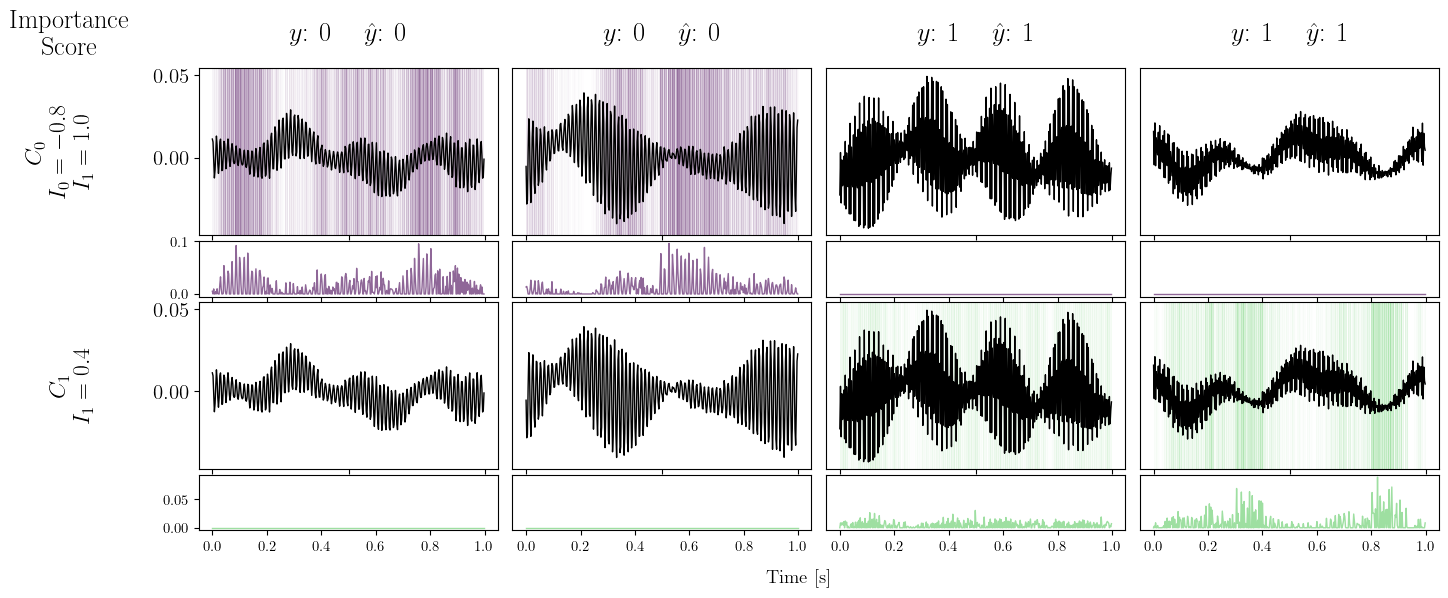

Plotting report on fourier domain


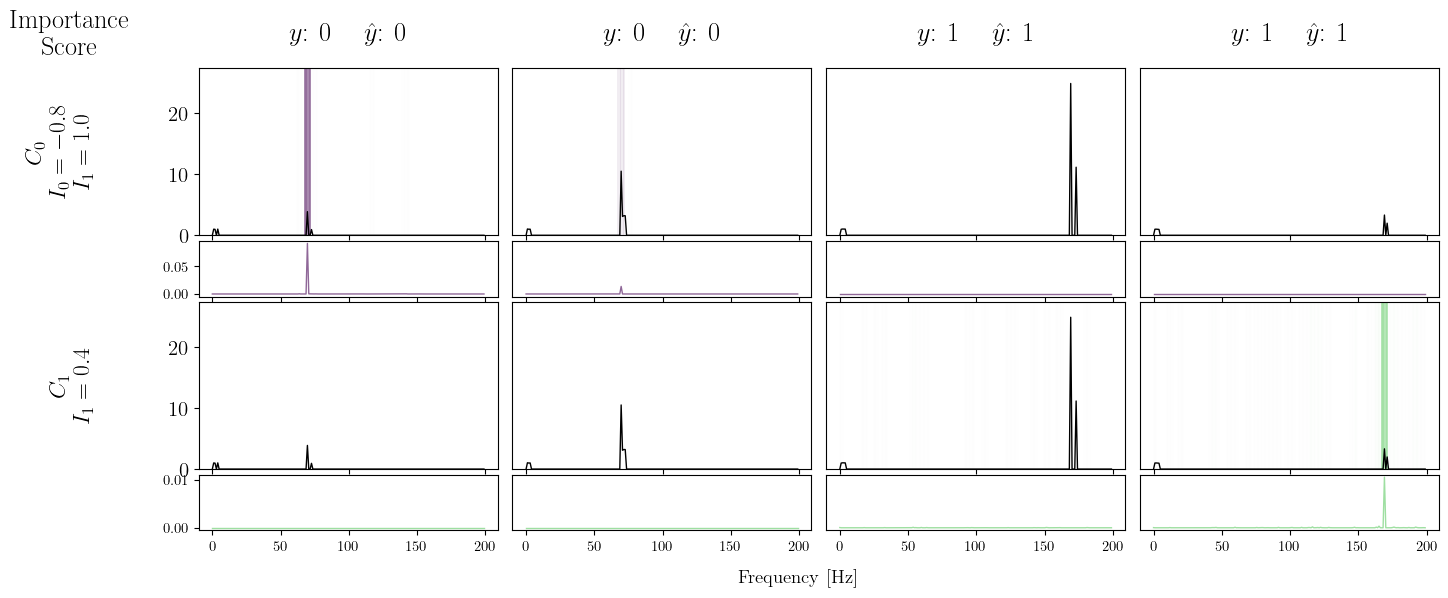

Plotting report on stft domain


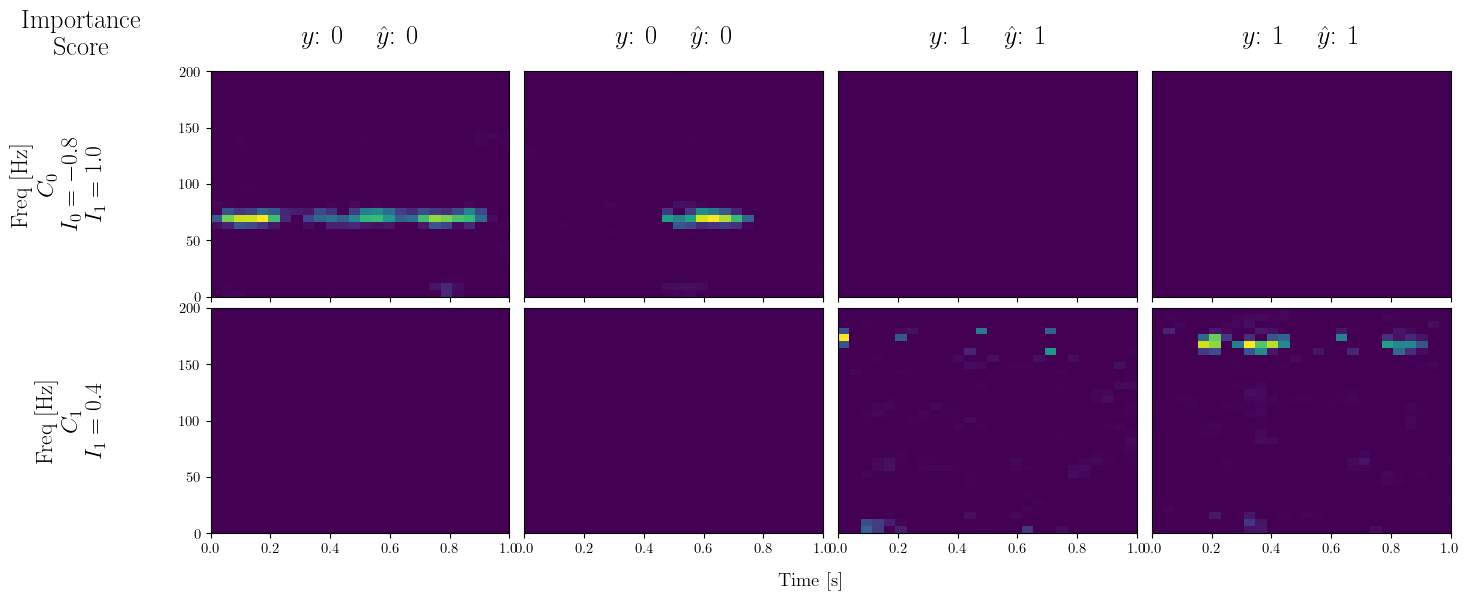

Plotting report on wavelet domain


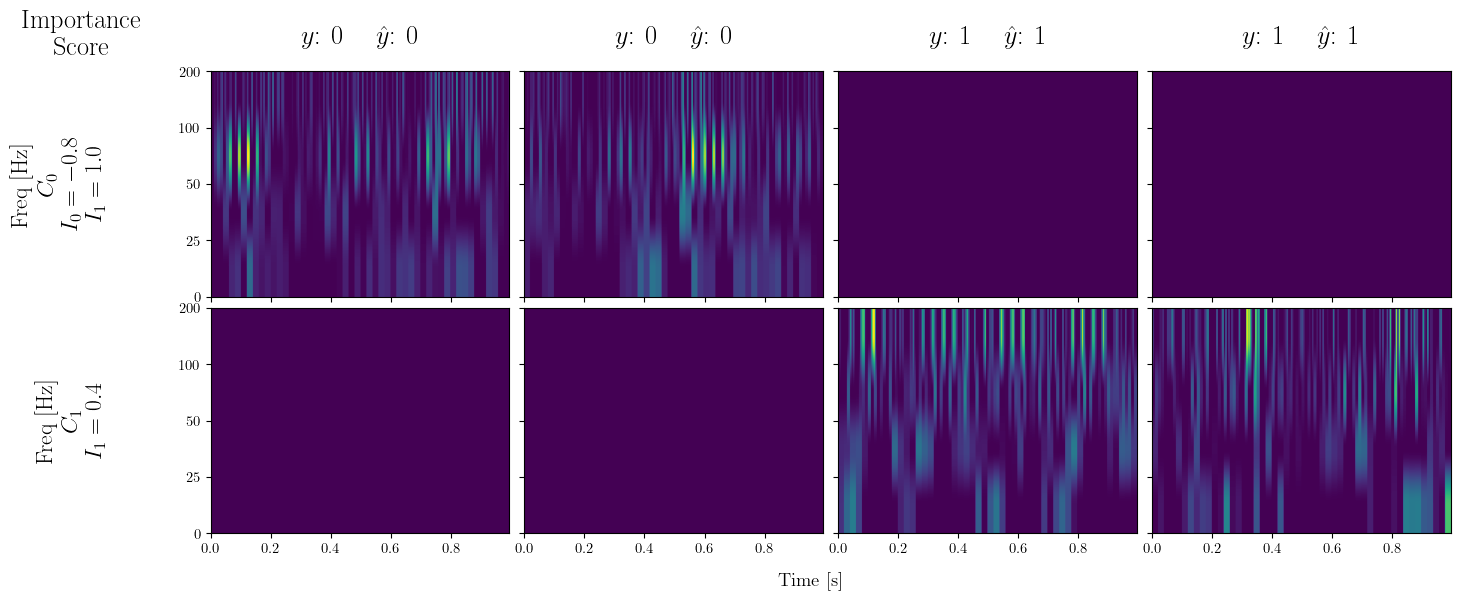

In [10]:
cfg.mode = "force-report"
ds_fs = getattr(cfg.dataset, "fs", None) or 1

if cfg.dataset.task == "classification":
    batch = sorted_inputs(CE.model, valid_loader, n_classes=cfg.dataset.n_classes, n_repeats=2)
elif cfg.dataset.task == "regression" and cfg.transforms.standardize:
    batch = sorted_inputs_regression(
        valid_loader, partitions=5, samples_per_partition=1, out_range=[-2, 2], int_out=cfg.CE.multilabel_out, astensor=True,
    )
else:
    batch = next(iter(valid_loader))

if isinstance(batch, dict):
    test_inputs, test_truth = batch["x"][:4], batch["y"][:4]
else:
    test_inputs, test_truth, _ = batch[:4]

for domain in cfg.CE.domain:
    print(f"Plotting report on {domain} domain")
    test_masks, test_outputs = CE.eval(
        test_inputs, domain=domain, device=device, outdevice="cpu",
        maskMode=getattr(cfg.CE, "maskMode", "none"), noisetunnel=False,
    )
    CE.report(
        test_masks, cfg.CE, test_inputs, test_outputs, domain=domain, fs=ds_fs,
        test_truth=test_truth, DS_cfg=cfg.dataset, font_base=5,
        destandardize=cfg.transforms.standardize, visualization_mode="perceptual",
        classwise_IS=True, use_clamp=False, importance_thr=0.5, show=True,
    )